# Test set results

This notebook scores the tuned remaining useful life (RUL) models on the 100 FD001 test engines. It is the only notebook that evaluates models on the test set, and it does so once: every hyperparameter and the choice of selected model were fixed by cross-validation in `03_models.ipynb` and are read from `results/best_params.json`. Nothing below is tuned, and no result here changes an earlier choice.

## Protocol

Each configuration is refitted on all 100 training engines with RUL capped at 125 cycles, the same target used in cross-validation. The engineered features need statistics fitted on training data (regime normalisation and the health-index model); these are fitted on the training engines and applied unchanged to the test engines.

The test trajectories stop at an unknown point before failure, and `RUL_FD001.txt` gives the true RUL only at each engine's last observed cycle. Features are computed over each test engine's full observed history, so rolling windows and slopes at the last cycle use the cycles before it, and the model then predicts once per engine at that last cycle. All 100 engines therefore carry equal weight. Predictions are scored against the true, uncapped RUL; late stage means true RUL of at most 50 cycles.

The models are the mean baseline, linear regression, and the selected configurations of Elastic Net, Random Forest, and XGBoost on both the raw and engineered feature sets.

In [1]:
import json
from itertools import pairwise
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

from rul.data import USEFUL_SENSORS, add_rul, load_fd
from rul.evaluate import evaluate, predict_last_cycle
from rul.features import feature_groups, make_features
from rul.models import build_model

RUL_CAP = 125
LATE_CUT = 50
WINDOWS = (5, 10, 20)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 220})


def save(fig, name):
    """Save a figure under figures/results_<name>.png."""
    fig.savefig(ROOT / "figures" / f"results_{name}.png", bbox_inches="tight", facecolor="white")

In [2]:
train, test, test_rul = load_fd("FD001")
train = add_rul(train, cap=RUL_CAP)

best_params = json.loads((ROOT / "results" / "best_params.json").read_text())
assert best_params["target_cap"] == RUL_CAP and best_params["sensors"] == USEFUL_SENSORS
assert tuple(best_params["windows"]) == WINDOWS

groups = feature_groups(USEFUL_SENSORS, WINDOWS)
FEATURE_SETS = {
    "raw": groups["raw"],
    "engineered": groups["raw"] + groups["rolling"] + groups["slope"] + groups["health"],
}

# Feature statistics are fitted on the 100 training engines only, then applied to the test engines.
# Rolling windows use each test engine's full observed history before its last cycle is taken.
train_feat, scaler = make_features(train, USEFUL_SENSORS, WINDOWS)
test_feat, _ = make_features(test, USEFUL_SENSORS, WINDOWS, scaler=scaler)

PARALLEL = {"random_forest": {"n_jobs": -1}, "xgboost": {"n_jobs": -1}, "elastic_net": {}}
LABELS = {"elastic_net": "Elastic Net", "random_forest": "Random Forest", "xgboost": "XGBoost"}
candidates = {("Mean baseline", "raw"): DummyRegressor()}
for feature_set in FEATURE_SETS:
    candidates[("Linear Regression", feature_set)] = LinearRegression()
    for name, label in LABELS.items():
        params = best_params["models"][f"{name}/{feature_set}"]["params"]
        candidates[(label, feature_set)] = build_model(name, **params, **PARALLEL[name])

predictions = {}
for (label, feature_set), model in candidates.items():
    features = FEATURE_SETS[feature_set]
    model.fit(train_feat[features], train_feat["rul"])
    predictions[(label, feature_set)] = predict_last_cycle(model, test_feat, features)
predictions = pd.DataFrame(predictions).rename_axis(columns=["model", "features"])
assert predictions.index.equals(test_rul.index) and len(predictions) == 100
print(f"{len(candidates)} models, {len(predictions)} test engines, "
      f"true RUL {test_rul.min()} to {test_rul.max()} cycles, "
      f"{(test_rul <= LATE_CUT).sum()} late (<= {LATE_CUT}), {(test_rul > RUL_CAP).sum()} above the cap")

9 models, 100 test engines, true RUL 7 to 145 cycles, 33 late (<= 50), 11 above the cap


## Results

The table scores every model on the same 100 engines against the true RUL. `cv_rmse` is the cross-validation RMSE from `03_models.ipynb`, repeated for reference. It is not directly comparable: cross-validation scores every cycle of the held-out training engines against the capped target, while the test score uses one cycle per engine against the uncapped label.

In [3]:
def score(truth, label):
    """One row of metrics per model, all scored against the same per-engine labels."""
    rows = {key: evaluate(truth, predictions[key], late_cut=LATE_CUT) for key in predictions}
    table = pd.DataFrame(rows).T.rename_axis(["model", "features"])
    return table.assign(scored_against=label).set_index("scored_against", append=True)


test_metrics = pd.concat([
    score(test_rul, "true RUL"),
    # Published FD001 results clip test labels at the same cap, so this block is for that comparison.
    score(test_rul.clip(upper=RUL_CAP), f"true RUL capped at {RUL_CAP}"),
])
cv = pd.read_csv(ROOT / "results" / "models_cv.csv")
cv = cv[cv["scored against"] == "capped RUL"].set_index(["model", "features"])["rmse_mean"]
cv = cv.rename(index=lambda m: LABELS.get(m, m), level=0)
test_metrics = test_metrics.join(cv.rename("cv_rmse"), on=["model", "features"])
test_metrics.xs("true RUL", level="scored_against")

,,rmse,mae,nasa_score,rmse_early,mae_early,rmse_late,mae_late,cv_rmse
model,features,,,,,,,,
Mean baseline,raw,43.067,35.900,33629.231,27.297,22.711,64.092,62.678,41.673
Linear Regression,raw,22.536,17.727,1291.370,21.927,16.689,23.724,19.833,20.119
Elastic Net,raw,22.572,17.770,1296.352,21.932,16.695,23.818,19.953,20.119
Random Forest,raw,17.772,13.214,533.563,19.423,15.338,13.828,8.901,16.433
XGBoost,raw,17.583,13.011,538.521,19.391,15.372,13.170,8.219,16.421
Linear Regression,engineered,18.233,14.103,518.853,19.689,14.803,14.845,12.682,17.066
Elastic Net,engineered,18.269,14.112,522.027,19.745,14.836,14.827,12.642,17.063
Random Forest,engineered,15.233,11.327,344.257,17.883,14.414,7.336,5.060,14.420
XGBoost,engineered,15.361,11.260,388.613,18.106,14.219,7.032,5.253,13.988


In [4]:
selected = (LABELS[best_params["selected"]["model"]], best_params["selected"]["features"])
print("Selected before the test set was opened:", selected)
test_metrics.xs("true RUL", level="scored_against").loc[[selected]]

Selected before the test set was opened: ('XGBoost', 'engineered')


,,rmse,mae,nasa_score,rmse_early,mae_early,rmse_late,mae_late,cv_rmse
model,features,,,,,,,,
XGBoost,engineered,15.361,11.26,388.613,18.106,14.219,7.032,5.253,13.988


The selected model, XGBoost on engineered features, reaches an RMSE of 15.36 cycles, an MAE of 11.26, and a NASA score of 389 on the test engines. In the late stage, where maintenance decisions are made, its RMSE is 7.03 cycles across the 33 engines with true RUL of at most 50.

Random Forest on engineered features is slightly better on the test set: RMSE 15.23 and a NASA score of 344, against 15.36 and 389. Cross-validation had ranked XGBoost first (13.99 against 14.42). XGBoost remains the selected model, because changing the choice after seeing test results would turn the test set into a second validation set and bias the reported error downwards. The bootstrap below checks whether the gap is larger than the sampling noise from having only 100 test engines.

The ordering found in cross-validation otherwise holds. Every model beats the mean baseline (RMSE 43.07), the tree ensembles beat the linear models on both feature sets, and the engineered features improve every model: XGBoost falls from 17.58 to 15.36, Random Forest from 17.77 to 15.23, and Elastic Net from 22.57 to 18.27. Elastic Net and linear regression are almost identical (18.27 and 18.23), as they were in cross-validation, because the selected penalty is very weak. The engineered features matter most in the late stage: XGBoost's late RMSE falls from 13.17 on raw features to 7.03.

In [5]:
# Paired bootstrap over test engines: resample the same engines for both models each time.
rng = np.random.default_rng(42)
draws = rng.integers(0, len(test_rul), size=(10_000, len(test_rul)))


def rmse_draws(key):
    """RMSE on each bootstrap resample of the 100 test engines."""
    error = (predictions[key] - test_rul).to_numpy()
    return np.sqrt((error[draws] ** 2).mean(axis=1))


pairs = {"Random Forest minus XGBoost": (("Random Forest", "engineered"), ("XGBoost", "engineered")),
         "XGBoost minus Elastic Net": (("XGBoost", "engineered"), ("Elastic Net", "engineered")),
         "XGBoost engineered minus raw": (("XGBoost", "engineered"), ("XGBoost", "raw"))}
bootstrap = pd.DataFrame({
    name: {"rmse difference": test_metrics.xs("true RUL", level="scored_against").loc[a, "rmse"]
           - test_metrics.xs("true RUL", level="scored_against").loc[b, "rmse"],
           "95% interval low": np.percentile(rmse_draws(a) - rmse_draws(b), 2.5),
           "95% interval high": np.percentile(rmse_draws(a) - rmse_draws(b), 97.5)}
    for name, (a, b) in pairs.items()}).T
bootstrap

,rmse difference,95% interval low,95% interval high
Random Forest minus XGBoost,-0.128,-1.345,1.145
XGBoost minus Elastic Net,-2.908,-4.802,-1.044
XGBoost engineered minus raw,-2.223,-4.355,-0.172


With 100 test engines, a difference of a fraction of a cycle can come from which engines happen to be in the test set. The paired bootstrap resamples the 100 engines with replacement 10,000 times, scores both models on the same resample each time, and reports the 2.5th and 97.5th percentiles of the RMSE difference.

The interval for Random Forest minus XGBoost, roughly −1.3 to +1.1 cycles, contains zero: the two tree ensembles cannot be told apart on this test set. The intervals for XGBoost against Elastic Net and for engineered against raw features lie entirely below zero, so the advantage of tree ensembles over the linear model, and of the engineered features over raw readings, is not explained by test-set sampling.

## Predicted and true RUL per engine

Engines are sorted by true RUL, so the black line rises from the engine closest to failure to the one furthest from it. The dashed line separates the late stage (left, 33 engines) from the early stage.

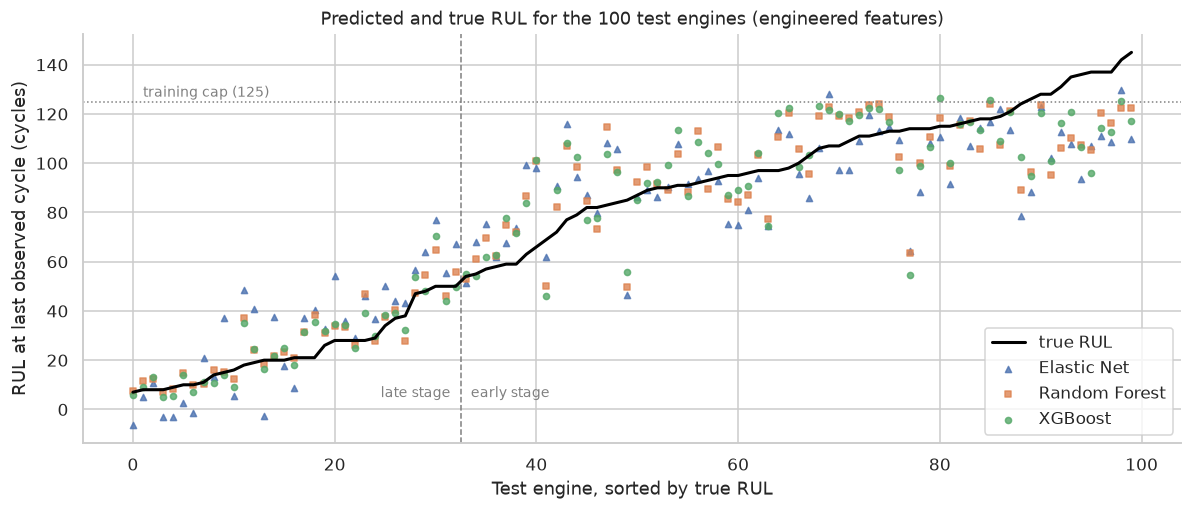

In [6]:
order = test_rul.sort_values().index
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(x, test_rul.loc[order], color="black", lw=2, label="true RUL", zorder=3)
for label, marker in (("Elastic Net", "^"), ("Random Forest", "s"), ("XGBoost", "o")):
    ax.scatter(x, predictions[(label, "engineered")].loc[order], s=16, marker=marker,
               alpha=0.8, label=label)
ax.axhline(RUL_CAP, color="grey", ls=":", lw=1)
ax.text(1, RUL_CAP + 2, f"training cap ({RUL_CAP})", color="grey", fontsize=9)
ax.axvline((test_rul <= LATE_CUT).sum() - 0.5, color="grey", ls="--", lw=1)
ax.text((test_rul <= LATE_CUT).sum() + 0.5, 5, "early stage", color="grey", fontsize=9)
ax.text((test_rul <= LATE_CUT).sum() - 1.5, 5, "late stage", color="grey", fontsize=9, ha="right")
ax.set(xlabel="Test engine, sorted by true RUL", ylabel="RUL at last observed cycle (cycles)",
       title="Predicted and true RUL for the 100 test engines (engineered features)")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "pred_vs_true")

Close to failure all three models track the true RUL closely; the tree ensembles stay within a few cycles for most late-stage engines, while Elastic Net scatters more widely and predicts slightly negative RUL for several engines near failure. Further from failure the spread grows for every model. At the right end the true RUL exceeds the training cap of 125 for 11 engines (up to 145), and no model predicts much above 125, because no training target was larger. These engines are underestimated by about 25 cycles by construction.

## Error by true RUL

The error is predicted minus true RUL, so a positive error means the model predicted failure later than it will happen, the costly direction. The table gives each model's RMSE within each bucket.

model,engines,Elastic Net,Random Forest,XGBoost
true RUL bucket,,,,
0 to 25,19,15.119,6.827,6.582
26 to 50,14,14.422,7.975,7.600
51 to 75,10,18.888,16.893,17.485
76 to 100,24,16.740,15.962,15.684
101 to 125,22,17.874,16.248,16.708
126 to 145,11,28.283,24.589,24.974


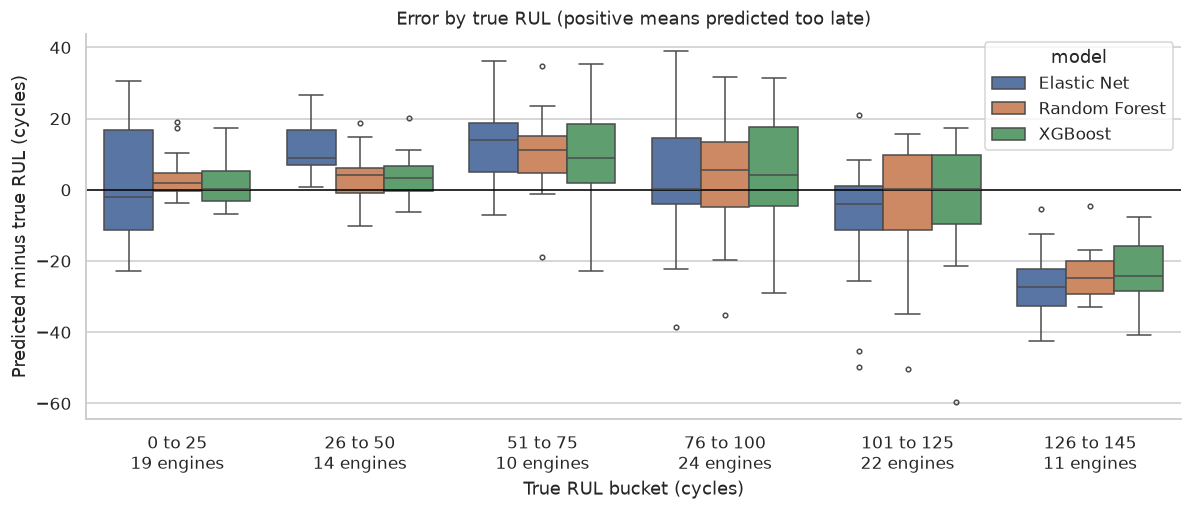

In [7]:
edges = [0, 25, 50, 75, 100, 125, test_rul.max()]
bucket_names = [f"{lo + 1 if lo else 0} to {hi}" for lo, hi in pairwise(edges)]
buckets = pd.cut(test_rul, bins=edges, labels=bucket_names, include_lowest=True)
errors = (predictions.xs("engineered", level="features", axis=1)
          [["Elastic Net", "Random Forest", "XGBoost"]].sub(test_rul, axis=0))
long = errors.assign(bucket=buckets.astype(str)).melt(
    id_vars="bucket", var_name="model", value_name="error")
bucket_order = [str(b) for b in buckets.cat.categories]

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.boxplot(data=long, x="bucket", y="error", hue="model", order=bucket_order, ax=ax,
            fliersize=3, linewidth=1)
ax.axhline(0, color="black", lw=1)
counts = buckets.value_counts().reindex(buckets.cat.categories)
ax.set_xticks(range(len(bucket_order)),
              [f"{b}\n{n} engines" for b, n in zip(bucket_order, counts)])
ax.set(xlabel="True RUL bucket (cycles)", ylabel="Predicted minus true RUL (cycles)",
       title="Error by true RUL (positive means predicted too late)")
fig.tight_layout()
save(fig, "error_by_bucket")

bucket_table = errors.groupby(buckets, observed=True).agg(
    lambda e: np.sqrt(np.mean(e**2))).rename_axis("true RUL bucket")
bucket_table.insert(0, "engines", counts.to_numpy())
bucket_table

For the two tree ensembles, the error is smallest close to failure: RMSE about 7 cycles for true RUL of at most 25, and about 8 between 26 and 50. Between 51 and 125 it rises to between 16 and 17.5, and above the cap to about 25. Elastic Net is close to the ensembles far from failure but about twice as inaccurate in the two late buckets, which is where the trees gain most.

The bucket from 51 to 75 cycles is the one where all three models lean late, with median errors of about +9 to +14 cycles. This is around where degradation first becomes visible in the sensors, and the models tend to treat an engine that has only started to degrade as healthier than it is. The bucket above 125 is biased the other way for the reason above: the cap makes the models underestimate. Underestimation brings maintenance forward but does not risk an in-service failure.

## Residual distribution

model,Elastic Net,Random Forest,XGBoost
mean error,-1.016,0.065,0.029
median error,-0.238,1.809,0.679
predicted too late,0.500,0.570,0.530
late by more than 20,11.000,6.000,9.000
early by more than 20,16.000,11.000,12.000
largest late error,38.900,34.770,35.225


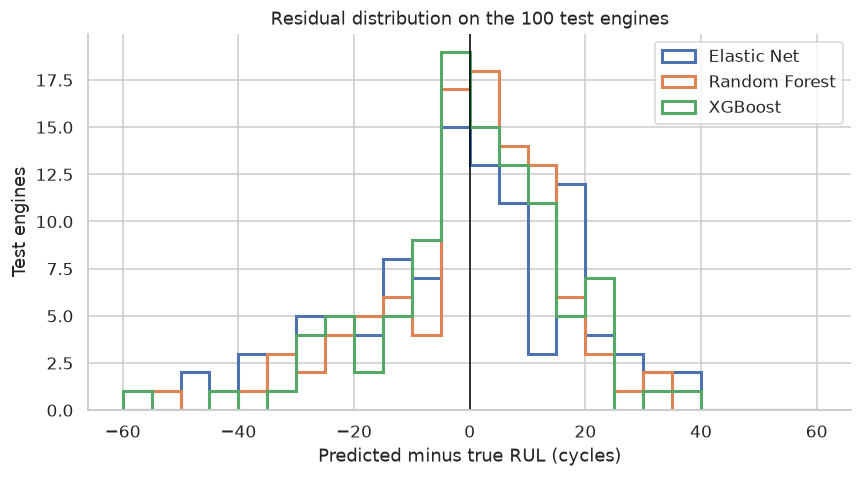

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.arange(-60, 61, 5)
for label in ("Elastic Net", "Random Forest", "XGBoost"):
    ax.hist(errors[label], bins=bins, histtype="step", lw=2, label=label)
ax.axvline(0, color="black", lw=1)
ax.set(xlabel="Predicted minus true RUL (cycles)", ylabel="Test engines",
       title="Residual distribution on the 100 test engines")
ax.legend()
fig.tight_layout()
save(fig, "residuals")

pd.DataFrame({
    "mean error": errors.mean(),
    "median error": errors.median(),
    "predicted too late": (errors > 0).mean(),
    "late by more than 20": (errors > 20).sum(),
    "early by more than 20": (errors < -20).sum(),
    "largest late error": errors.max(),
}).T

All three residual distributions are centred close to zero (mean errors between −1.0 and +0.1 cycles) and roughly half of the predictions are late. The left tails are longer than the right ones, partly because of the engines above the cap. On the costly side, 6 Random Forest predictions, 9 XGBoost predictions, and 11 Elastic Net predictions are more than 20 cycles late, and the largest late error is about 35 cycles for both ensembles. These late errors dominate the NASA score, which grows exponentially with lateness; this is why Random Forest's score (344) is lower than XGBoost's (389) even though their RMSEs are almost equal.

## Comparison with published FD001 results

Published FD001 results typically train on RUL capped at 125 (piecewise linear target) and score one prediction per test engine, the same protocol as here. Many also clip the test labels at the cap, and papers do not always state which labels they score against. To compare like with like, our models are therefore also rescored against the test RUL clipped at 125 (the second block of `results/test_metrics.csv`). The published values are every FD001 row with both RMSE and score in Table III of Ragab et al. (2020), except an SVM baseline (RMSE 40.72): Random Forest, gradient boosting and the MODBNE ensemble from Zhang et al. (2017), a 2D CNN from Babu et al. (2016), a deep LSTM from Zheng et al. (2017), LSTMBS from Liao et al. (2018), the 1D CNN of Li et al. (2018), BiLSTM-ED from Yu et al. (2019), CNN-LSTM from Wu et al. (2019), BLCNN from Liu et al. (2019), HDNN from Al-Dulaimi et al. (2019), and ATS2S from Ragab et al. (2020).

In [9]:
# Every FD001 row with both RMSE and score in Ragab et al. (2020), Table III, except SVM.
published = pd.DataFrame([
    ("Random Forest", "Zhang et al. 2017", 17.91, 480),
    ("Gradient Boosting", "Zhang et al. 2017", 15.67, 474),
    ("2D CNN", "Babu et al. 2016", 18.45, 1287),
    ("Deep LSTM", "Zheng et al. 2017", 16.14, 338),
    ("1D CNN", "Li et al. 2018", 12.61, 274),
    ("MODBNE", "Zhang et al. 2017", 15.04, 334),
    ("LSTMBS", "Liao et al. 2018", 14.89, 481),
    ("BiLSTM-ED", "Yu et al. 2019", 14.74, 273),
    ("CNN-LSTM", "Wu et al. 2019", 14.40, 290),
    ("BLCNN", "Liu et al. 2019", 13.18, 302),
    ("HDNN", "Al-Dulaimi et al. 2019", 13.02, 245),
    ("ATS2S", "Ragab et al. 2020", 12.63, 243),
], columns=["method", "source", "rmse", "nasa_score"]).assign(where="published")
capped = test_metrics.xs(f"true RUL capped at {RUL_CAP}", level="scored_against")
ours = pd.DataFrame([
    (f"{label} (ours)", f"{feature_set} features", capped.loc[(label, feature_set), "rmse"],
     capped.loc[(label, feature_set), "nasa_score"])
    for label, feature_set in [("Elastic Net", "engineered"), ("Random Forest", "engineered"),
                               ("XGBoost", "engineered")]
], columns=["method", "source", "rmse", "nasa_score"]).assign(where="this project")
comparison = pd.concat([published, ours]).sort_values("rmse").reset_index(drop=True)
comparison

,method,source,rmse,nasa_score,where
0,1D CNN,Li et al. 2018,12.610,274.000,published
1,ATS2S,Ragab et al. 2020,12.630,243.000,published
2,HDNN,Al-Dulaimi et al. 2019,13.020,245.000,published
3,BLCNN,Liu et al. 2019,13.180,302.000,published
4,Random Forest (ours),engineered features,14.023,309.535,this project
5,XGBoost (ours),engineered features,14.080,346.956,this project
6,CNN-LSTM,Wu et al. 2019,14.400,290.000,published
7,BiLSTM-ED,Yu et al. 2019,14.740,273.000,published
8,LSTMBS,Liao et al. 2018,14.890,481.000,published
9,MODBNE,Zhang et al. 2017,15.040,334.000,published


Scored on the same terms, Random Forest (RMSE 14.02, score 310) and XGBoost (14.08, score 347) rank fifth and sixth by RMSE among the twelve published results and our two ensembles. They are better than the published Random Forest (17.91) and gradient boosting (15.67) of Zhang et al. (2017) and than six deep models: CNN-LSTM (14.40), BiLSTM-ED (14.74), LSTMBS (14.89), MODBNE (15.04), the deep LSTM (16.14) and the 2D CNN (18.45). Our own raw-feature models score 16.58 (Random Forest) and 16.37 (XGBoost) against the same labels, so in our setting most of the improvement comes from the engineered features rather than from the choice of learner.

Four published deep models are more accurate: the 1D CNN of Li et al. (12.61), ATS2S (12.63), HDNN (13.02) and BLCNN (13.18), between 0.8 and 1.4 cycles of RMSE ahead of our Random Forest. On the NASA score our position is weaker. Six published models score lower than our Random Forest's 310: those four, plus BiLSTM-ED (273) and CNN-LSTM (290), which have a higher RMSE than ours but fewer costly late predictions. MODBNE (334) and the deep LSTM (338) also score lower than XGBoost (347).

The models ahead of ours learn features from fixed-length windows of the sensor sequence instead of using hand-designed rolling statistics; phase 2 of this project tests sequence models of this kind. Published numbers also differ in details that are not always reported, such as the window length and how short test histories are handled, so differences of a fraction of a cycle should not be read as meaningful.

## Summary

- The selected XGBoost model reaches a test RMSE of 15.36 cycles against the true RUL (14.08 against labels clipped at 125), and 7.03 cycles in the late stage.
- Random Forest is equally accurate on the test set; the 0.13-cycle gap in its favour is well inside the bootstrap interval. The selection was not changed after seeing the test results.
- Engineered features and tree ensembles both give gains that are larger than the test-set sampling noise.
- Errors are smallest close to failure, largest for engines whose true RUL exceeds the training cap, and the costly late errors cluster where degradation is just beginning.
- On the published protocol, the tree ensembles beat the published classical results and six of the ten published deep models on RMSE, and are 0.8 to 1.4 cycles behind four deep models (RMSE 12.61 to 13.18). On the NASA score, six published models are better than our best.

The figures are saved as `figures/results_*.png`; the metrics as `results/test_metrics.csv`, the per-engine predictions as `results/test_predictions.csv`, and the published comparison as `results/test_published_comparison.csv`.

In [10]:
test_metrics.to_csv(ROOT / "results" / "test_metrics.csv")
predictions.set_axis([f"{m}/{f}" for m, f in predictions.columns], axis=1).assign(
    true_rul=test_rul).to_csv(ROOT / "results" / "test_predictions.csv")
comparison.to_csv(ROOT / "results" / "test_published_comparison.csv", index=False)
print("Saved results/test_metrics.csv, test_predictions.csv, test_published_comparison.csv")

Saved results/test_metrics.csv, test_predictions.csv, test_published_comparison.csv
